In [12]:
# ============================================================================
# CELL 1: IMPORTS & SYSTEM SETUP
# ============================================================================
import os, sys, random, pickle, json, time, copy
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torch.optim import AdamW
from torch.cuda.amp import GradScaler, autocast

from transformers import (
    AutoTokenizer, AutoModel,
    get_cosine_schedule_with_warmup,
)
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (
    accuracy_score, f1_score, balanced_accuracy_score,
    precision_score, recall_score, cohen_kappa_score, matthews_corrcoef,
    classification_report, confusion_matrix,
)

try:
    import shap
    SHAP_AVAILABLE = True
except ImportError:
    SHAP_AVAILABLE = False
    print("⚠️  shap not installed. Run: pip install shap")

def set_seed(seed=42):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = True

set_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("="*80)
print("SYSTEM INFORMATION")
print("="*80)
print(f"PyTorch:      {torch.__version__}")
print(f"CUDA avail:   {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"CUDA device:  {torch.cuda.get_device_name(0)}")
    print(f"CUDA memory:  {torch.cuda.get_device_properties(0).total_memory/1e9:.2f} GB")
print(f"Using device: {device}")
print("="*80)

SYSTEM INFORMATION
PyTorch:      2.6.0+cu126
CUDA avail:   True
CUDA device:  NVIDIA GeForce RTX 3070
CUDA memory:  8.59 GB
Using device: cuda


In [ ]:
# ============================================================================
# CELL 2: CONFIGURATION — IDENTICAL to baseline paper configuration
# ============================================================================
class Config:
    BASE_MODEL        = "xlm-roberta"
    XLMBERT_PATH      = "xlm-roberta-base"

    PROJECT_DIR       = os.getcwd()
    DATA_DIR          = os.path.join(PROJECT_DIR, "Common_Dataset")
    TRAIN_PATH        = os.path.join(DATA_DIR, "train.csv")
    DEV_PATH          = os.path.join(DATA_DIR, "dev.csv")
    TEST_PATH         = os.path.join(DATA_DIR, "test.csv")

    BASE_DIR          = os.path.join(PROJECT_DIR, "hienbert_xai_refinement_results")
    MODEL_DIR         = os.path.join(BASE_DIR, "models")
    VISUALIZATION_DIR = os.path.join(BASE_DIR, "visualizations")
    RESULTS_DIR       = os.path.join(BASE_DIR, "results")
    SHAP_DIR          = os.path.join(BASE_DIR, "shap_outputs")
    for p in [BASE_DIR, MODEL_DIR, VISUALIZATION_DIR, RESULTS_DIR, SHAP_DIR]:
        os.makedirs(p, exist_ok=True)

    MAX_LENGTH        = 128
    BATCH_SIZE        = 32
    EPOCHS            = 15
    LEARNING_RATE     = 2e-5
    DROPOUT           = 0.3
    WEIGHT_DECAY      = 0.01
    GRADIENT_ACCUMULATION_STEPS = 1
    WARMUP_RATIO      = 0.1
    USE_AMP           = True
    NUM_WORKERS       = 0
    PIN_MEMORY        = True

    EARLY_STOPPING_PATIENCE = 5
    EARLY_STOPPING_MIN_DELTA = 0.001

    DEVICE            = device
    SEED              = 42
    HF_TOKEN = os.getenv("HF_TOKEN")

print("="*80)
print("XAI REFINEMENT CONFIGURATION")
print("="*80)
print(f"BATCH_SIZE={Config.BATCH_SIZE}  EPOCHS={Config.EPOCHS}  LR={Config.LEARNING_RATE}")
print(f"DROPOUT={Config.DROPOUT}  WEIGHT_DECAY={Config.WEIGHT_DECAY}  "
      f"WARMUP={Config.WARMUP_RATIO}  MAX_LEN={Config.MAX_LENGTH}")
print(f"EARLY_STOP_PATIENCE={Config.EARLY_STOPPING_PATIENCE}  AMP={Config.USE_AMP}")
print("="*80)

XAI REFINEMENT CONFIGURATION
BATCH_SIZE=32  EPOCHS=15  LR=2e-05
DROPOUT=0.3  WEIGHT_DECAY=0.01  WARMUP=0.1  MAX_LEN=128
EARLY_STOP_PATIENCE=5  AMP=True


In [14]:
# ============================================================================
# CELL 3: DATA LOADING & PREPROCESSING
# ============================================================================
class Preprocessor:
    def __init__(self):
        self.le_primary  = LabelEncoder()
        self.le_subcat   = LabelEncoder()
        self.le_severity = LabelEncoder()
        self.column_mapping = {
            "primary_category":  "category_primary",
            "secondary_category":"category_secondary",
            "Severity":          "severity",
            "Complaint_Title":   "complaint_title",
            "Text_en":           "text_en",
            "Text_hi":           "Hindi",
            "Text_hinglish":     "Hinglish",
        }

    def _rename(self, df):
        return df.rename(columns={k:v for k,v in self.column_mapping.items() if k in df.columns})

    def _build_text(self, df):
        df = self._rename(df)
        cols = ["complaint_title", "text_en", "Hindi", "Hinglish"]
        for c in cols:
            if c in df.columns:
                df[c] = df[c].fillna("").astype(str)
        avail = [c for c in cols if c in df.columns]
        df["text"] = df[avail].agg(" ".join, axis=1)
        df["text"] = df["text"].str.replace(r"\s+", " ", regex=True).str.strip()
        return df.dropna(subset=["category_primary","category_secondary","severity"]).reset_index(drop=True)

    def fit_transform(self, tr, dv, te):
        tr = self._build_text(tr); dv = self._build_text(dv); te = self._build_text(te)
        self.le_primary.fit(tr["category_primary"])
        self.le_subcat.fit(tr["category_secondary"])
        self.le_severity.fit(tr["severity"])
        for df in (tr, dv, te):
            df["primary_label"]  = self.le_primary.transform(df["category_primary"])
            df["subcat_label"]   = self.le_subcat.transform(df["category_secondary"])
            df["severity_label"] = self.le_severity.transform(df["severity"])
        print(f"Primary classes: {len(self.le_primary.classes_)} | "
              f"Subcat: {len(self.le_subcat.classes_)} | "
              f"Severity: {len(self.le_severity.classes_)}")
        return tr, dv, te

train_df = pd.read_csv(Config.TRAIN_PATH)
dev_df   = pd.read_csv(Config.DEV_PATH)
test_df  = pd.read_csv(Config.TEST_PATH)
preprocessor = Preprocessor()
train_df, dev_df, test_df = preprocessor.fit_transform(train_df, dev_df, test_df)

print(f"Split sizes -> Train: {len(train_df)}  Dev: {len(dev_df)}  Test: {len(test_df)}")

Primary classes: 8 | Subcat: 24 | Severity: 3
Split sizes -> Train: 14165  Dev: 3035  Test: 3036


In [15]:
# ============================================================================
# CELL 4: TOKENIZER + PRE-TOKENIZED DATASETS
# ============================================================================
tokenizer = AutoTokenizer.from_pretrained(
    Config.XLMBERT_PATH, token=Config.HF_TOKEN, use_fast=True
)
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

print("Pre-tokenizing all splits once...")

class PreTokenizedComplaintDataset(Dataset):
    def __init__(self, df, tokenizer, max_length=128, tag="split"):
        self.primary   = torch.tensor(df["primary_label"].values,  dtype=torch.long)
        self.subcat    = torch.tensor(df["subcat_label"].values,   dtype=torch.long)
        self.severity  = torch.tensor(df["severity_label"].values, dtype=torch.long)
        self.sentiment = torch.zeros(len(df), dtype=torch.float)
        texts = df["text"].astype(str).tolist()
        t0 = time.time()
        enc = tokenizer(
            texts, truncation=True, padding="max_length",
            max_length=max_length, return_tensors="pt"
        )
        self.input_ids      = enc["input_ids"]
        self.attention_mask = enc["attention_mask"]
        print(f"  [{tag}] tokenized {len(df)} samples in {time.time()-t0:.1f}s "
              f"-> {tuple(self.input_ids.shape)}")

    def __len__(self): return len(self.primary)

    def __getitem__(self, i):
        return {
            "input_ids":      self.input_ids[i],
            "attention_mask": self.attention_mask[i],
            "primary":        self.primary[i],
            "subcat":         self.subcat[i],
            "severity":       self.severity[i],
            "sentiment":      self.sentiment[i],
        }


class TokenDropoutDataset(Dataset):
    """
    SHAP wrapper: randomly mask SHAP-identified spurious tokens.
    Caches the precomputed spurious mask to disk so repeated runs are fast.
    """
    def __init__(self, base_ds, spurious_token_ids, pad_id, p_drop=0.3,
                 cache_path=None):
        self.ds = base_ds
        self.pad_id = pad_id
        self.p_drop = p_drop

        cache_file = cache_path or f"{Config.MODEL_DIR}/spurious_masks.pt"
        if os.path.exists(cache_file):
            self.spurious_masks = torch.load(cache_file, weights_only=False)
            print(f"  [TokenDropoutDataset] loaded cached mask ({len(self.spurious_masks)} rows)")
        else:
            spurious_t = torch.tensor(sorted(spurious_token_ids), dtype=torch.long)
            masks = [torch.isin(self.ds[i]["input_ids"], spurious_t)
                     for i in range(len(self.ds))]
            self.spurious_masks = masks
            try:
                torch.save(masks, cache_file)
                print(f"  [TokenDropoutDataset] computed & cached mask for {len(masks)} rows")
            except Exception as e:
                print(f"  [TokenDropoutDataset] could not cache mask: {e}")

    def __len__(self): return len(self.ds)

    def __getitem__(self, i):
        item = self.ds[i]
        mask = self.spurious_masks[i]
        if mask.any() and torch.rand(1).item() < self.p_drop:
            ids = item["input_ids"].clone()
            ids[mask] = self.pad_id
            item = dict(item); item["input_ids"] = ids
        return item


TRAIN_DS = PreTokenizedComplaintDataset(train_df, tokenizer, Config.MAX_LENGTH, "train")
DEV_DS   = PreTokenizedComplaintDataset(dev_df,   tokenizer, Config.MAX_LENGTH, "dev")
TEST_DS  = PreTokenizedComplaintDataset(test_df,  tokenizer, Config.MAX_LENGTH, "test")

Pre-tokenizing all splits once...
  [train] tokenized 14165 samples in 4.1s -> (14165, 128)
  [dev] tokenized 3035 samples in 1.0s -> (3035, 128)
  [test] tokenized 3036 samples in 1.1s -> (3036, 128)


In [16]:
# ============================================================================
# CELL 5: MODEL DEFINITIONS  (attention pooling — fp32, no SDPA quirks)
# ============================================================================
class HiEnBERT_Baseline(nn.Module):
    def __init__(self, base_model, n_primary, n_subcat, n_severity, dropout=0.2):
        super().__init__()
        self.base = base_model
        h = base_model.config.hidden_size
        self.hidden_size = h
        self.dropout = nn.Dropout(dropout)
        self.shared = nn.Linear(h, h)
        self.gelu   = nn.GELU()
        self.fc_primary  = nn.Linear(h, n_primary)
        self.fc_subcat   = nn.Linear(h, n_subcat)
        self.fc_severity = nn.Linear(h, n_severity)
        self.n_primary, self.n_subcat, self.n_severity = n_primary, n_subcat, n_severity
        self._init_weights()

    def _init_weights(self):
        for m in [self.fc_primary, self.fc_subcat, self.fc_severity, self.shared]:
            nn.init.xavier_uniform_(m.weight)
            nn.init.zeros_(m.bias)

    def forward(self, input_ids, attention_mask, sentiment=None):
        out = self.base(input_ids=input_ids, attention_mask=attention_mask)
        cls = out.last_hidden_state[:, 0, :]
        x = self.gelu(self.shared(cls))
        x = self.dropout(x)
        return self.fc_primary(x), self.fc_subcat(x), self.fc_severity(x)


class HiEnBERT_SHAPRefined(HiEnBERT_Baseline):
    """
    SHAP-refined HiEnBERT. Adds only the modules SHAP decided on.
    All flags False → mathematically identical to baseline.

    `_attention_pool` is fp32, uses plain softmax + masked_fill(-1e9),
    so no fp16 overflow and no SDPA mask-shape issues.
    """
    def __init__(self, base_model, n_primary, n_subcat, n_severity, dropout=0.2,
                 use_negation_gate=False, use_residual=False,
                 use_attention_pooling=False):
        super().__init__(base_model, n_primary, n_subcat, n_severity, dropout)
        self.use_negation_gate     = use_negation_gate
        self.use_residual          = use_residual
        self.use_attention_pooling = use_attention_pooling
        h = self.hidden_size
        if use_attention_pooling:
            self.pool_query = nn.Linear(h, 1, bias=False)
            self.pool_proj  = nn.Linear(h, h)
            nn.init.xavier_uniform_(self.pool_query.weight)
            nn.init.xavier_uniform_(self.pool_proj.weight)
            nn.init.zeros_(self.pool_proj.bias)
        if use_negation_gate:
            self.negation_gate = nn.Linear(h, h)
            nn.init.xavier_uniform_(self.negation_gate.weight)
            nn.init.zeros_(self.negation_gate.bias)

    def _attention_pool(self, tokens, attention_mask):
        B, T, H = tokens.shape
        h  = tokens.float()
        w_q = self.pool_query.weight.view(1, 1, H).float()
        scores = (h * w_q).sum(dim=-1)                     # (B, T) fp32
        scores = scores.masked_fill(attention_mask == 0, -1e9)
        attn   = torch.softmax(scores, dim=-1).unsqueeze(-1)
        pooled = (h * attn).sum(dim=1)
        return pooled.to(tokens.dtype)

    def forward(self, input_ids, attention_mask, sentiment=None):
        out    = self.base(input_ids=input_ids, attention_mask=attention_mask)
        tokens = out.last_hidden_state
        cls    = tokens[:, 0, :]

        if self.use_attention_pooling:
            pooled = self._attention_pool(tokens, attention_mask)
            cls = cls + self.pool_proj(pooled)

        x = self.gelu(self.shared(cls))
        if self.use_residual:
            x = x + cls
        if self.use_negation_gate:
            gate = torch.sigmoid(self.negation_gate(x))
            x = x * gate
        x = self.dropout(x)
        return self.fc_primary(x), self.fc_subcat(x), self.fc_severity(x)

In [17]:
# ============================================================================
# CELL 6: TRAINING + EVALUATION FUNCTIONS
# ============================================================================
class EarlyStopping:
    def __init__(self, patience=5, min_delta=0.001, mode="max"):
        self.patience, self.min_delta, self.mode = patience, min_delta, mode
        self.counter, self.best_score, self.early_stop = 0, None, False

    def __call__(self, score):
        if self.best_score is None:
            self.best_score = score; return False
        improvement = (score - self.best_score) if self.mode == "max" \
                      else (self.best_score - score)
        if improvement > self.min_delta:
            self.best_score = score; self.counter = 0
        else:
            self.counter += 1
            if self.counter >= self.patience:
                self.early_stop = True
        return self.early_stop


def train_epoch(model, loader, optimizer, scheduler, criterion, scaler):
    model.train()
    total_loss, task_loss = 0.0, {"primary":0.,"subcat":0.,"severity":0.}
    all_preds, all_labels = [], []
    optimizer.zero_grad()
    pbar = tqdm(loader, desc="Train", leave=False)
    for bidx, batch in enumerate(pbar):
        ids  = batch["input_ids"].to(Config.DEVICE, non_blocking=True)
        am   = batch["attention_mask"].to(Config.DEVICE, non_blocking=True)
        sent = batch["sentiment"].to(Config.DEVICE, non_blocking=True)
        y1   = batch["primary"].to(Config.DEVICE, non_blocking=True)
        y2   = batch["subcat"].to(Config.DEVICE, non_blocking=True)
        y3   = batch["severity"].to(Config.DEVICE, non_blocking=True)

        if scaler is not None:
            with autocast():
                p1, p2, p3 = model(ids, am, sent)
                loss, ldict = criterion(p1, p2, p3, y1, y2, y3)
        else:
            p1, p2, p3 = model(ids, am, sent)
            loss, ldict = criterion(p1, p2, p3, y1, y2, y3)

        loss = loss / Config.GRADIENT_ACCUMULATION_STEPS
        if scaler is not None:
            scaler.scale(loss).backward()
        else:
            loss.backward()

        if (bidx + 1) % Config.GRADIENT_ACCUMULATION_STEPS == 0:
            if scaler is not None:
                scaler.unscale_(optimizer)
                torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                scaler.step(optimizer); scaler.update()
            else:
                torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                optimizer.step()
            scheduler.step(); optimizer.zero_grad(set_to_none=True)

        total_loss += loss.item() * Config.GRADIENT_ACCUMULATION_STEPS
        for k in task_loss: task_loss[k] += ldict[k]
        preds = p1.argmax(dim=1)
        all_preds.extend(preds.cpu().numpy()); all_labels.extend(y1.cpu().numpy())
        pbar.set_postfix({"loss": f"{loss.item()*Config.GRADIENT_ACCUMULATION_STEPS:.3f}"})

    avg = total_loss / len(loader)
    acc = accuracy_score(all_labels, all_preds)
    bal = balanced_accuracy_score(all_labels, all_preds)
    for k in task_loss: task_loss[k] /= len(loader)
    return avg, acc, bal, task_loss


def evaluate(model, loader, return_metrics=True):
    model.eval()
    P1, P2, P3, L1, L2, L3, confs = [], [], [], [], [], [], []
    with torch.no_grad():
        for batch in tqdm(loader, desc="Eval", leave=False):
            ids  = batch["input_ids"].to(Config.DEVICE, non_blocking=True)
            am   = batch["attention_mask"].to(Config.DEVICE, non_blocking=True)
            p1, p2, p3 = model(ids, am)
            P1.extend(p1.argmax(1).cpu().numpy()); L1.extend(batch["primary"].numpy())
            P2.extend(p2.argmax(1).cpu().numpy()); L2.extend(batch["subcat"].numpy())
            P3.extend(p3.argmax(1).cpu().numpy()); L3.extend(batch["severity"].numpy())
            confs.extend(torch.softmax(p1, dim=1).max(1)[0].cpu().numpy())

    m = {
        "primary_acc":  accuracy_score(L1, P1),
        "primary_bal":  balanced_accuracy_score(L1, P1),
        "primary_f1":   f1_score(L1, P1, average="weighted", zero_division=0),
        "primary_f1m":  f1_score(L1, P1, average="macro",     zero_division=0),
        "primary_prec": precision_score(L1, P1, average="weighted", zero_division=0),
        "primary_rec":  recall_score(L1, P1, average="weighted", zero_division=0),
        "primary_kappa":cohen_kappa_score(L1, P1),
        "primary_mcc":  matthews_corrcoef(L1, P1),
        "subcat_acc":   accuracy_score(L2, P2),
        "subcat_f1":    f1_score(L2, P2, average="weighted", zero_division=0),
        "severity_acc": accuracy_score(L3, P3),
        "severity_f1":  f1_score(L3, P3, average="weighted", zero_division=0),
    }
    m["overall_acc"] = float(np.mean([m["primary_acc"], m["subcat_acc"], m["severity_acc"]]))
    if return_metrics:
        return m, P1, L1
    return m


def train_full(model, train_loader, val_loader, test_loader, tag):
    optimizer = AdamW(model.parameters(), lr=Config.LEARNING_RATE,
                      weight_decay=Config.WEIGHT_DECAY, betas=(0.9, 0.999), eps=1e-8)
    total_steps = len(train_loader) * Config.EPOCHS // Config.GRADIENT_ACCUMULATION_STEPS
    scheduler = get_cosine_schedule_with_warmup(
        optimizer,
        num_warmup_steps=int(Config.WARMUP_RATIO * total_steps),
        num_training_steps=total_steps,
    )
    scaler = GradScaler() if Config.USE_AMP and torch.cuda.is_available() else None
    es     = EarlyStopping(patience=Config.EARLY_STOPPING_PATIENCE)

    class MultiTaskLoss(nn.Module):
        def __init__(self):
            super().__init__()
            self.l1 = nn.CrossEntropyLoss()
            self.l2 = nn.CrossEntropyLoss()
            self.l3 = nn.CrossEntropyLoss()
        def forward(self, p1, p2, p3, y1, y2, y3):
            a = self.l1(p1, y1); b = self.l2(p2, y2); c = 0.5 * self.l3(p3, y3)
            return a + b + c, {"primary":a.item(), "subcat":b.item(), "severity":c.item()}
    crit = MultiTaskLoss()

    history = {"train_loss": [], "train_acc": [], "val_acc": [], "val_f1": []}
    best_f1 = 0.0; best_state = None; best_epoch = -1
    t_start = time.time()

    print(f"\n{'='*70}\nTraining: {tag}\n{'='*70}")
    for epoch in range(Config.EPOCHS):
        ep_t = time.time()
        loss, tr_acc, tr_bal, _ = train_epoch(
            model, train_loader, optimizer, scheduler, crit, scaler
        )
        vm, _, _ = evaluate(model, val_loader)
        history["train_loss"].append(loss)
        history["train_acc"].append(tr_acc)
        history["val_acc"].append(vm["primary_acc"])
        history["val_f1"].append(vm["primary_f1"])

        print(f"Epoch {epoch+1:2d}/{Config.EPOCHS}: "
              f"train_loss={loss:.4f}  train_acc={tr_acc:.4f}  "
              f"val_acc={vm['primary_acc']:.4f}  val_f1={vm['primary_f1']:.4f}  "
              f"({time.time()-ep_t:.0f}s)")

        if vm["primary_f1"] > best_f1:
            best_f1, best_epoch = vm["primary_f1"], epoch + 1
            best_state = copy.deepcopy(model.state_dict())
            print(f"  ✓ new best val F1 = {best_f1:.4f}")

        if es(vm["primary_f1"]):
            print(f"  Early stopping at epoch {epoch+1} (patience={Config.EARLY_STOPPING_PATIENCE})")
            break

    if best_state is not None:
        model.load_state_dict(best_state)

    test_m, _, _ = evaluate(model, test_loader)
    elapsed = time.time() - t_start
    print(f"\n[{tag}] Test: primary_acc={test_m['primary_acc']:.4f}  "
          f"overall_acc={test_m['overall_acc']:.4f}  best_val_f1={best_f1:.4f}  "
          f"epoch={best_epoch}  time={elapsed/60:.1f} min")

    return {
        "tag":          tag,
        "metrics":      test_m,
        "best_val_f1":  best_f1,
        "best_epoch":   best_epoch,
        "train_time_s": elapsed,
        "history":      history,
        "best_state_dict": best_state,
    }

In [18]:
# ============================================================================
# CELL 7: SHAP INSIGHT EXTRACTOR (GradientExplainer FIXED)
# ============================================================================
class SHAPInsightExtractor:
    def __init__(self, model, tokenizer, class_names, device, max_length=128):
        self.model, self.tokenizer = model, tokenizer
        self.class_names, self.device, self.max_length = class_names, device, max_length
        self.insights = {}

    def _predict_primary(self, texts):
        self.model.eval()
        enc = self.tokenizer(
            list(texts), truncation=True, padding="max_length",
            max_length=self.max_length, return_tensors="pt"
        ).to(self.device)
        with torch.no_grad():
            p1, _, _ = self.model(enc["input_ids"], enc["attention_mask"])
            return torch.softmax(p1, dim=1).cpu().numpy()

    def token_importances(self, sample_texts, nsamples=200):
        print("[SHAP] token-level importances...")
        masker    = shap.maskers.Text(self.tokenizer)
        explainer = shap.Explainer(self._predict_primary, masker)
        sv        = explainer(sample_texts, max_evals=nsamples)
        imp = {}
        for i in range(sv.values.shape[0]):
            for tok, v in zip(sv.data[i], np.abs(sv.values[i]).mean(axis=-1)):
                t = str(tok).strip().lower()
                if len(t) < 2: continue
                imp[t] = imp.get(t, 0.0) + float(v)
        total = sum(imp.values()) or 1.0
        imp = {k: v / total for k, v in imp.items()}
        imp = dict(sorted(imp.items(), key=lambda x: -x[1]))
        self.insights["token_importance"] = imp
        print(f"  Top-15: {list(imp.keys())[:15]}")
        return imp

    def class_profiles(self, texts_per_class, n_per_class=30):
        print("[SHAP] per-class token profiles...")
        profiles = {}
        for ci, cname in enumerate(self.class_names):
            texts = texts_per_class.get(cname, [])[:n_per_class]
            if not texts: continue
            def _pred_c(ts, _c=ci):
                return self._predict_primary(ts)[:, _c]
            masker    = shap.maskers.Text(self.tokenizer)
            explainer = shap.Explainer(_pred_c, masker)
            sv        = explainer(texts, max_evals=100)
            scores = {}
            for i in range(sv.values.shape[0]):
                for tok, v in zip(sv.data[i], sv.values[i]):
                    t = str(tok).strip().lower()
                    if len(t) < 2: continue
                    scores[t] = scores.get(t, 0.0) + float(v)
            top = sorted(scores.items(), key=lambda x: -x[1])[:15]
            profiles[cname] = top
            print(f"  {cname}: {[t for t,_ in top[:5]]}")
        self.insights["class_profiles"] = profiles
        return profiles

    def embedding_dims(self, sample_texts, n_background=50, n_target=100):
        print("[SHAP] embedding-dimension importances...")
        self.model.eval()

        def _encode(texts):
            enc = self.tokenizer(
                list(texts), truncation=True, padding="max_length",
                max_length=self.max_length, return_tensors="pt",
            ).to(self.device)
            with torch.no_grad():
                return self.model.base(**enc).last_hidden_state[:, 0, :]

        bg = _encode(sample_texts[:n_background])
        tg = _encode(sample_texts[n_background:n_background + n_target])

        class _HeadStack(nn.Module):
            def __init__(self, host_model):
                super().__init__()
                self.host = host_model
            def forward(self, emb):
                x  = self.host.gelu(self.host.shared(emb))
                p1 = torch.softmax(self.host.fc_primary(x),  dim=1)
                p2 = torch.softmax(self.host.fc_subcat(x),   dim=1)
                p3 = torch.softmax(self.host.fc_severity(x), dim=1)
                return torch.cat([p1, p2, p3], dim=1)

        head_module = _HeadStack(self.model).to(self.device)
        expl = shap.GradientExplainer(head_module, bg)
        sv   = expl.shap_values(tg)
        sv   = np.array(sv) if not isinstance(sv, list) else np.stack(sv)
        if sv.ndim == 4:
            sv = sv.squeeze(0)
        dim_imp = np.abs(sv).mean(axis=0)
        if dim_imp.ndim > 1:
            dim_imp = dim_imp.mean(axis=-1)

        self.insights["embedding_dims"] = {
            "top_dims": np.argsort(-dim_imp)[:20].tolist(),
            "full_importance": dim_imp.tolist(),
        }
        print(f"  Top-20 dims: {self.insights['embedding_dims']['top_dims']}")
        return self.insights["embedding_dims"]

    def run(self, test_df, text_col="text_en"):
        print("\n" + "="*70 + "\nSTAGE 1: SHAP DIAGNOSIS\n" + "="*70)
        sample = test_df[text_col].fillna("").astype(str).tolist()[:200]
        self.token_importances(sample)
        texts_per_class = {}
        for cname in self.class_names:
            sub = test_df[test_df["category_primary"] == cname] \
                  if "category_primary" in test_df.columns else pd.DataFrame()
            texts_per_class[cname] = sub[text_col].fillna("").astype(str).tolist()
        self.class_profiles(texts_per_class)
        self.embedding_dims(sample)
        return self.insights

In [20]:
# ============================================================================
# CELL 9: BUILD LOADERS + BASE MODEL FACTORY
# ============================================================================
def build_loaders(train_ds_override=None):
    tr_ds = train_ds_override or TRAIN_DS
    tr_loader = DataLoader(tr_ds,  batch_size=Config.BATCH_SIZE,   shuffle=True,
                           num_workers=0, pin_memory=Config.PIN_MEMORY)
    dv_loader = DataLoader(DEV_DS, batch_size=Config.BATCH_SIZE*2, shuffle=False,
                           num_workers=0, pin_memory=Config.PIN_MEMORY)
    te_loader = DataLoader(TEST_DS,batch_size=Config.BATCH_SIZE*2, shuffle=False,
                           num_workers=0, pin_memory=Config.PIN_MEMORY)
    return tr_loader, dv_loader, te_loader

def fresh_base():
    return AutoModel.from_pretrained(Config.XLMBERT_PATH, token=Config.HF_TOKEN)

In [21]:
# ============================================================================
# CELL 10: LOAD baseline from disk if it exists; else train once.
# ============================================================================
N_PRIMARY   = len(preprocessor.le_primary.classes_)
N_SUBCAT    = len(preprocessor.le_subcat.classes_)
N_SEVERITY  = len(preprocessor.le_severity.classes_)
CLASS_NAMES = list(preprocessor.le_primary.classes_)

BASELINE_CKPT     = f"{Config.MODEL_DIR}/baseline_best.pt"
BASELINE_METADATA = f"{Config.MODEL_DIR}/baseline_metadata.json"

def _load_metadata(path):
    if not os.path.exists(path): return None
    with open(path, "r") as f:
        try: return json.load(f)
        except Exception: return None

def _save_metadata(path, obj):
    def _c(o):
        if isinstance(o, dict): return {k:_c(v) for k,v in o.items()}
        if isinstance(o, (np.floating, np.integer)): return float(o)
        if isinstance(o, np.ndarray): return o.tolist()
        if isinstance(o, (list, tuple)): return [_c(x) for x in o]
        return o
    with open(path, "w") as f: json.dump(_c(obj), f, indent=2)

def _is_valid_metric(x):
    try:
        if x is None: return False
        return np.isfinite(float(x))
    except Exception:
        return False

baseline_model = HiEnBERT_Baseline(
    base_model=fresh_base(), n_primary=N_PRIMARY, n_subcat=N_SUBCAT,
    n_severity=N_SEVERITY, dropout=Config.DROPOUT,
).to(Config.DEVICE)

if os.path.exists(BASELINE_CKPT):
    print("\n" + "="*70)
    print("STAGE 0: LOADING BASELINE FROM DISK (no retraining)")
    print("="*70)
    baseline_model.load_state_dict(torch.load(BASELINE_CKPT, map_location=Config.DEVICE))
    baseline_model.eval()

    meta = _load_metadata(BASELINE_METADATA)
    _, dv_l0, te_l0 = build_loaders()

    if meta is None or "metrics" not in meta or meta.get("metrics") is None:
        print("  ⚠️  metadata missing — recomputing TEST metrics")
        test_m, _, _ = evaluate(baseline_model, te_l0)
    else:
        test_m = meta["metrics"]
        print("  ✓ test metrics loaded from metadata")

    best_val_f1_meta = (meta or {}).get("best_val_f1")
    if not _is_valid_metric(best_val_f1_meta):
        print("  ⚠️  best_val_f1 missing/NaN — recomputing from DEV split")
        val_m, _, _ = evaluate(baseline_model, dv_l0)
        best_val_f1 = float(val_m["primary_f1"])
    else:
        best_val_f1 = float(best_val_f1_meta)

    best_epoch = (meta or {}).get("best_epoch", -1)
    train_time = (meta or {}).get("train_time_s", 0.0)
    history    = (meta or {}).get(
        "history", {"train_loss": [], "train_acc": [], "val_acc": [], "val_f1": []})

    baseline_result = {
        "tag": "baseline",
        "metrics": test_m,
        "best_val_f1": best_val_f1,
        "best_epoch": best_epoch if best_epoch is not None else -1,
        "train_time_s": train_time if train_time is not None else 0.0,
        "history": history,
        "best_state_dict": baseline_model.state_dict(),
    }
    _save_metadata(BASELINE_METADATA, {
        "metrics":      baseline_result["metrics"],
        "best_val_f1":  baseline_result["best_val_f1"],
        "best_epoch":   baseline_result["best_epoch"],
        "train_time_s": baseline_result["train_time_s"],
        "history":      baseline_result["history"],
        "recovered_at": time.strftime("%Y-%m-%d %H:%M:%S"),
    })
    print(f"\n  Baseline: primary_acc={baseline_result['metrics']['primary_acc']:.4f}  "
          f"overall_acc={baseline_result['metrics']['overall_acc']:.4f}  "
          f"best_val_f1={baseline_result['best_val_f1']:.4f}")
else:
    print("\n" + "="*70)
    print("STAGE 0: NO BASELINE ON DISK → TRAIN ONE")
    print("="*70)
    tr_l0, dv_l0, te_l0 = build_loaders()
    baseline_result = train_full(baseline_model, tr_l0, dv_l0, te_l0, tag="baseline")
    torch.save(baseline_result["best_state_dict"], BASELINE_CKPT)
    _save_metadata(BASELINE_METADATA, {
        "metrics":       baseline_result["metrics"],
        "best_val_f1":   baseline_result["best_val_f1"],
        "best_epoch":    baseline_result["best_epoch"],
        "train_time_s":  baseline_result["train_time_s"],
        "history":       baseline_result["history"],
    })
    baseline_model.load_state_dict(baseline_result["best_state_dict"])

print(f"\nBaseline ready. Best val F1 = {baseline_result['best_val_f1']:.4f}")

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 7107.17it/s]
[transformers] XLMRobertaModel LOAD REPORT from: xlm-roberta-base
Key                       | Status     |  | 
--------------------------+------------+--+-
lm_head.bias              | UNEXPECTED |  | 
lm_head.layer_norm.weight | UNEXPECTED |  | 
lm_head.dense.weight      | UNEXPECTED |  | 
lm_head.layer_norm.bias   | UNEXPECTED |  | 
lm_head.dense.bias        | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.



STAGE 0: LOADING BASELINE FROM DISK (no retraining)
  ✓ test metrics loaded from metadata

  Baseline: primary_acc=0.9368  overall_acc=0.8950  best_val_f1=0.9342

Baseline ready. Best val F1 = 0.9342


In [22]:
# ============================================================================
# CELL 11: SHAP DIAGNOSIS + TRANSLATION (resumable)
# ============================================================================
INSIGHTS_JSON = f"{Config.SHAP_DIR}/baseline_insights.json"

extractor = SHAPInsightExtractor(
    baseline_model, tokenizer, CLASS_NAMES, Config.DEVICE, Config.MAX_LENGTH
)

if os.path.exists(INSIGHTS_JSON):
    print("\n" + "="*70)
    print("STAGE 1: LOADING PREVIOUSLY SAVED SHAP INSIGHTS")
    print("="*70)
    with open(INSIGHTS_JSON, "r") as f:
        insights = json.load(f)
    for cname, prof in insights.get("class_profiles", {}).items():
        insights["class_profiles"][cname] = [(t[0], t[1]) for t in prof]
    print(f"  ✓ Loaded: {len(insights.get('token_importance', {}))} tokens, "
          f"{len(insights.get('class_profiles', {}))} class profiles, "
          f"embedding_dims={'yes' if 'embedding_dims' in insights else 'no'}")
else:
    insights = extractor.run(test_df, text_col="text_en")

with open(INSIGHTS_JSON, "w") as f:
    def _c(o):
        if isinstance(o, dict): return {k:_c(v) for k,v in o.items()}
        if isinstance(o,(np.floating,np.integer)): return float(o)
        if isinstance(o, np.ndarray): return o.tolist()
        if isinstance(o, (list, tuple)): return [_c(x) for x in o]
        return o
    json.dump(_c(insights), f, indent=2)
print(f"✓ SHAP insights saved -> {INSIGHTS_JSON}")

translator = SHAPTranslator(insights)
decisions = translator.translate()

use_negation_gate     = any(d["type"]=="negation_gate"     for d in decisions)
use_residual          = any(d["type"]=="residual_shared"   for d in decisions)
use_attention_pooling = any(d["type"]=="attention_pooling" for d in decisions)
spurious_tokens       = set()
for d in decisions:
    if d["type"] == "token_dropout":
        spurious_tokens.update(d.get("tokens", []))

spurious_ids = []
for tok in spurious_tokens:
    sub = tokenizer.tokenize(tok)
    if sub:
        tid = tokenizer.convert_tokens_to_ids(sub[0])
        if tid is not None and tid >= 0:
            spurious_ids.append(tid)
spurious_ids = set(spurious_ids)

print(f"\nModel flags from SHAP:")
print(f"  use_negation_gate     = {use_negation_gate}")
print(f"  use_residual          = {use_residual}")
print(f"  use_attention_pooling = {use_attention_pooling}")
print(f"  token_dropout on {len(spurious_ids)} token ids "
      f"(samples: {list(spurious_tokens)[:6]})")


STAGE 1: LOADING PREVIOUSLY SAVED SHAP INSIGHTS
  ✓ Loaded: 1885 tokens, 8 class profiles, embedding_dims=yes
✓ SHAP insights saved -> C:\Users\CH.SC.U4CSE23160\Final_Year_Project\hienbert_xai_refinement_results\shap_outputs/baseline_insights.json

STAGE 2: SHAP → MODEL DECISIONS
  [1] token_dropout: Tokens ['the', 'in'] shared across ≥4 class profiles → spurious/boilerplate; apply token dropout.
  [2] attention_pooling: Token importance very sparse (Gini=0.72) → add attention-pooling over tokens.

Model flags from SHAP:
  use_negation_gate     = False
  use_residual          = False
  use_attention_pooling = True
  token_dropout on 2 token ids (samples: ['in', 'the'])


In [23]:
# ============================================================================
# CELL 12: STAGE 3 — TRAIN SHAP-REFINED MODEL
#   - Skips training if the checkpoint already exists on disk.
#   - Prints per-batch timing breakdown BEFORE training so we can confirm
#     the model runs at baseline speed.
# ============================================================================
print("\n" + "="*70 + "\nSTAGE 3: TRAIN SHAP-REFINED MODEL\n" + "="*70)

REFINED_CKPT     = f"{Config.MODEL_DIR}/shap_refined_best.pt"
REFINED_METADATA = f"{Config.MODEL_DIR}/shap_refined_metadata.json"

refined_model = HiEnBERT_SHAPRefined(
    base_model=fresh_base(),
    n_primary=N_PRIMARY, n_subcat=N_SUBCAT, n_severity=N_SEVERITY,
    dropout=Config.DROPOUT,
    use_negation_gate=use_negation_gate,
    use_residual=use_residual,
    use_attention_pooling=use_attention_pooling,
).to(Config.DEVICE)

if os.path.exists(REFINED_CKPT):
    print("\n  ✓ Found existing shap_refined_best.pt — loading (no retraining)")
    refined_model.load_state_dict(torch.load(REFINED_CKPT, map_location=Config.DEVICE))
    refined_model.eval()
    meta_r = _load_metadata(REFINED_METADATA) or {}
    _, _, te_lr = build_loaders()
    test_m_r, _, _ = evaluate(refined_model, te_lr)
    refined_result = {
        "tag": "shap_refined",
        "metrics": test_m_r,
        "best_val_f1": meta_r.get("best_val_f1", 0.0),
        "best_epoch":  meta_r.get("best_epoch", -1),
        "train_time_s": meta_r.get("train_time_s", 0.0),
        "history":      meta_r.get("history", {"train_loss": [], "train_acc": [], "val_acc": [], "val_f1": []}),
        "best_state_dict": refined_model.state_dict(),
    }
    print(f"  ✓ Loaded: primary_acc={refined_result['metrics']['primary_acc']:.4f}  "
          f"overall_acc={refined_result['metrics']['overall_acc']:.4f}  "
          f"best_val_f1={refined_result['best_val_f1']:.4f}")

else:
    print("\n  No checkpoint found — training from scratch.")

    # ----------------------------------------------------------------------
    # Per-batch timing probe (2 minutes) — confirms the pooling head is not
    # the bottleneck before we commit to a 1h40m training run.
    # ----------------------------------------------------------------------
    print("\n  [TIMING PROBE] benchmarking one batch forward+backward...")
    _probe_baseline = HiEnBERT_Baseline(
        base_model=fresh_base(),
        n_primary=N_PRIMARY, n_subcat=N_SUBCAT, n_severity=N_SEVERITY,
        dropout=Config.DROPOUT,
    ).to(Config.DEVICE)

    _probe_loader = build_loaders()[0]
    _batch = next(iter(_probe_loader))
    _ids = _batch["input_ids"].to(Config.DEVICE)
    _am  = _batch["attention_mask"].to(Config.DEVICE)
    _y1  = _batch["primary"].to(Config.DEVICE)
    _y2  = _batch["subcat"].to(Config.DEVICE)
    _y3  = _batch["severity"].to(Config.DEVICE)
    _loss_fn = nn.CrossEntropyLoss()

    def _time_probe(model, n_iter=20, label="model"):
        model.train()
        opt = torch.optim.AdamW(model.parameters(), lr=2e-5)
        sc  = GradScaler() if Config.USE_AMP else None
        for _ in range(3):
            opt.zero_grad()
            with autocast(enabled=Config.USE_AMP):
                p1, p2, p3 = model(_ids, _am)
                loss = _loss_fn(p1,_y1)+_loss_fn(p2,_y2)+0.5*_loss_fn(p3,_y3)
            if sc: sc.scale(loss).backward(); sc.step(opt); sc.update()
            else:  loss.backward(); opt.step()
        torch.cuda.synchronize()
        t0 = time.time()
        for _ in range(n_iter):
            opt.zero_grad()
            with autocast(enabled=Config.USE_AMP):
                p1, p2, p3 = model(_ids, _am)
                loss = _loss_fn(p1,_y1)+_loss_fn(p2,_y2)+0.5*_loss_fn(p3,_y3)
            if sc: sc.scale(loss).backward(); sc.step(opt); sc.update()
            else:  loss.backward(); opt.step()
        torch.cuda.synchronize()
        dt = (time.time()-t0)/n_iter
        print(f"    [{label:30s}] {dt*1000:7.1f} ms/batch  (≈ {dt*443/60:5.2f} min/epoch)")
        return dt

    _t_base = _time_probe(_probe_baseline, label="baseline")
    _t_ref  = _time_probe(refined_model,  label="shap_refined")
    print(f"    Overhead: {(_t_ref - _t_base)*1000:+.1f} ms/batch\n")
    del _probe_baseline
    torch.cuda.empty_cache()

    # ----------------------------------------------------------------------
    # Full training
    # ----------------------------------------------------------------------
    base_train_ds = TRAIN_DS
    if spurious_ids:
        train_ds_refined = TokenDropoutDataset(base_train_ds, spurious_ids,
                                               tokenizer.pad_token_id, p_drop=0.3)
    else:
        train_ds_refined = base_train_ds

    tr_l_ref, dv_l_ref, te_l_ref = build_loaders(train_ds_override=train_ds_refined)

    refined_result = train_full(
        refined_model, tr_l_ref, dv_l_ref, te_l_ref, tag="shap_refined"
    )
    torch.save(refined_result["best_state_dict"], REFINED_CKPT)
    _save_metadata(REFINED_METADATA, {
        "metrics":       refined_result["metrics"],
        "best_val_f1":   refined_result["best_val_f1"],
        "best_epoch":    refined_result["best_epoch"],
        "train_time_s":  refined_result["train_time_s"],
        "history":       refined_result["history"],
    })
    print(f"✓ SHAP-refined model trained and saved -> {REFINED_CKPT}")


STAGE 3: TRAIN SHAP-REFINED MODEL


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 10469.06it/s]
[transformers] XLMRobertaModel LOAD REPORT from: xlm-roberta-base
Key                       | Status     |  | 
--------------------------+------------+--+-
lm_head.bias              | UNEXPECTED |  | 
lm_head.layer_norm.weight | UNEXPECTED |  | 
lm_head.dense.weight      | UNEXPECTED |  | 
lm_head.layer_norm.bias   | UNEXPECTED |  | 
lm_head.dense.bias        | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.



  No checkpoint found — training from scratch.

  [TIMING PROBE] benchmarking one batch forward+backward...


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 7107.23it/s]
[transformers] XLMRobertaModel LOAD REPORT from: xlm-roberta-base
Key                       | Status     |  | 
--------------------------+------------+--+-
lm_head.bias              | UNEXPECTED |  | 
lm_head.layer_norm.weight | UNEXPECTED |  | 
lm_head.dense.weight      | UNEXPECTED |  | 
lm_head.layer_norm.bias   | UNEXPECTED |  | 
lm_head.dense.bias        | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


    [baseline                      ]   566.1 ms/batch  (≈  4.18 min/epoch)
    [shap_refined                  ]  1029.0 ms/batch  (≈  7.60 min/epoch)
    Overhead: +462.9 ms/batch

  [TokenDropoutDataset] computed & cached mask for 14165 rows

Training: shap_refined


Epoch  1/15: train_loss=3.9631  train_acc=0.5793  val_acc=0.8689  val_f1=0.8688  (146s)
  ✓ new best val F1 = 0.8688


... (11 outputs left out)

Epoch 13/15: train_loss=0.0806  train_acc=0.9956  val_acc=0.9331  val_f1=0.9330  (449s)


Epoch 14/15: train_loss=0.0708  train_acc=0.9966  val_acc=0.9334  val_f1=0.9334  (450s)


Epoch 15/15: train_loss=0.0697  train_acc=0.9964  val_acc=0.9325  val_f1=0.9324  (450s)



[shap_refined] Test: primary_acc=0.9361  overall_acc=0.8962  best_val_f1=0.9373  epoch=11  time=99.3 min
✓ SHAP-refined model trained and saved -> C:\Users\CH.SC.U4CSE23160\Final_Year_Project\hienbert_xai_refinement_results\models/shap_refined_best.pt


In [24]:
# ============================================================================
# CELL 13: STAGE 4 — CLOSED-LOOP VALIDATION
# ============================================================================
print("\n" + "="*70 + "\nSTAGE 4: CLOSED-LOOP VALIDATION\n" + "="*70)

metric_keys = ["primary_acc","primary_bal","primary_f1","primary_f1m",
               "primary_prec","primary_rec","primary_kappa","primary_mcc",
               "subcat_acc","subcat_f1","severity_acc","severity_f1","overall_acc"]

rows = []
for name, res in [("Baseline", baseline_result), ("SHAP-Refined", refined_result)]:
    row = {"Variant": name}
    row.update({k: float(res["metrics"][k]) for k in metric_keys})
    row["Best Val F1"]  = float(res["best_val_f1"])
    row["Best Epoch"]   = int(res["best_epoch"])
    row["Train Time (min)"] = float(res["train_time_s"]/60)
    rows.append(row)

comparison_df = pd.DataFrame(rows)
print("\n" + comparison_df.round(4).to_string(index=False))

print("\nΔ (SHAP-Refined − Baseline):")
for k in metric_keys + ["Best Val F1"]:
    v = comparison_df.iloc[1][k] - comparison_df.iloc[0][k]
    arrow = "↑" if v > 0 else ("↓" if v < 0 else "=")
    print(f"  {k:20s}  {v:+.4f}  {arrow}")

comparison_df.to_csv(f"{Config.RESULTS_DIR}/xai_refinement_comparison.csv", index=False)
with open(f"{Config.RESULTS_DIR}/xai_refinement_full.json", "w") as f:
    json.dump({
        "config": {
            "batch_size": Config.BATCH_SIZE, "epochs": Config.EPOCHS,
            "lr": Config.LEARNING_RATE, "dropout": Config.DROPOUT,
            "weight_decay": Config.WEIGHT_DECAY, "warmup_ratio": Config.WARMUP_RATIO,
            "max_length": Config.MAX_LENGTH, "amp": Config.USE_AMP,
            "early_stopping_patience": Config.EARLY_STOPPING_PATIENCE,
        },
        "decisions": decisions,
        "baseline":  {k: float(baseline_result["metrics"][k]) for k in metric_keys},
        "refined":   {k: float(refined_result["metrics"][k])  for k in metric_keys},
        "baseline_best_val_f1": float(baseline_result["best_val_f1"]),
        "refined_best_val_f1":  float(refined_result["best_val_f1"]),
        "baseline_best_epoch":  int(baseline_result["best_epoch"]),
        "refined_best_epoch":   int(refined_result["best_epoch"]),
    }, f, indent=2)
print(f"\n✓ Comparison saved -> {Config.RESULTS_DIR}/xai_refinement_comparison.csv")


STAGE 4: CLOSED-LOOP VALIDATION

     Variant  primary_acc  primary_bal  primary_f1  primary_f1m  primary_prec  primary_rec  primary_kappa  primary_mcc  subcat_acc  subcat_f1  severity_acc  severity_f1  overall_acc  Best Val F1  Best Epoch  Train Time (min)
    Baseline       0.9368       0.9396      0.9368       0.9381        0.9373       0.9368         0.9270       0.9271      0.8607     0.8607        0.8877       0.8884       0.8950       0.9342          -1            0.0000
SHAP-Refined       0.9361       0.9389      0.9360       0.9377        0.9364       0.9361         0.9262       0.9263      0.8626     0.8625        0.8900       0.8907       0.8962       0.9373          11           99.2953

Δ (SHAP-Refined − Baseline):
  primary_acc           -0.0007  ↓
  primary_bal           -0.0008  ↓
  primary_f1            -0.0009  ↓
  primary_f1m           -0.0004  ↓
  primary_prec          -0.0010  ↓
  primary_rec           -0.0007  ↓
  primary_kappa         -0.0008  ↓
  primary_mcc   

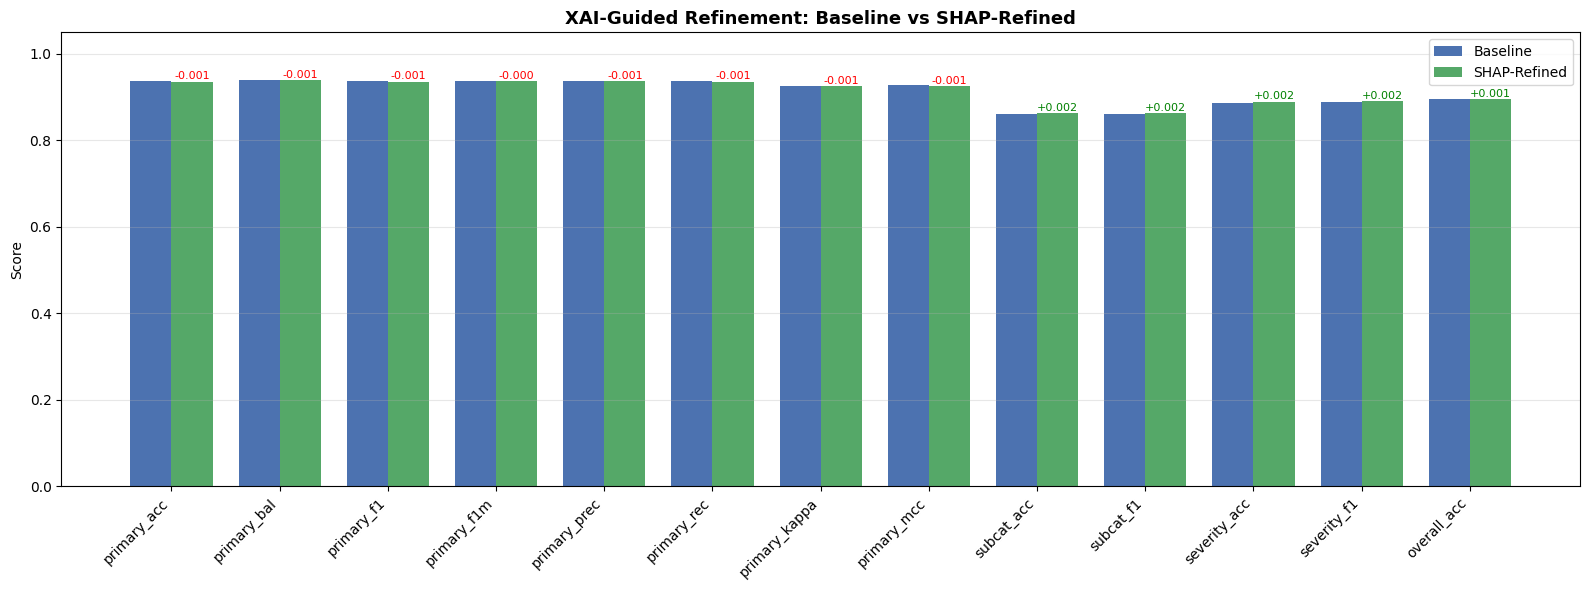

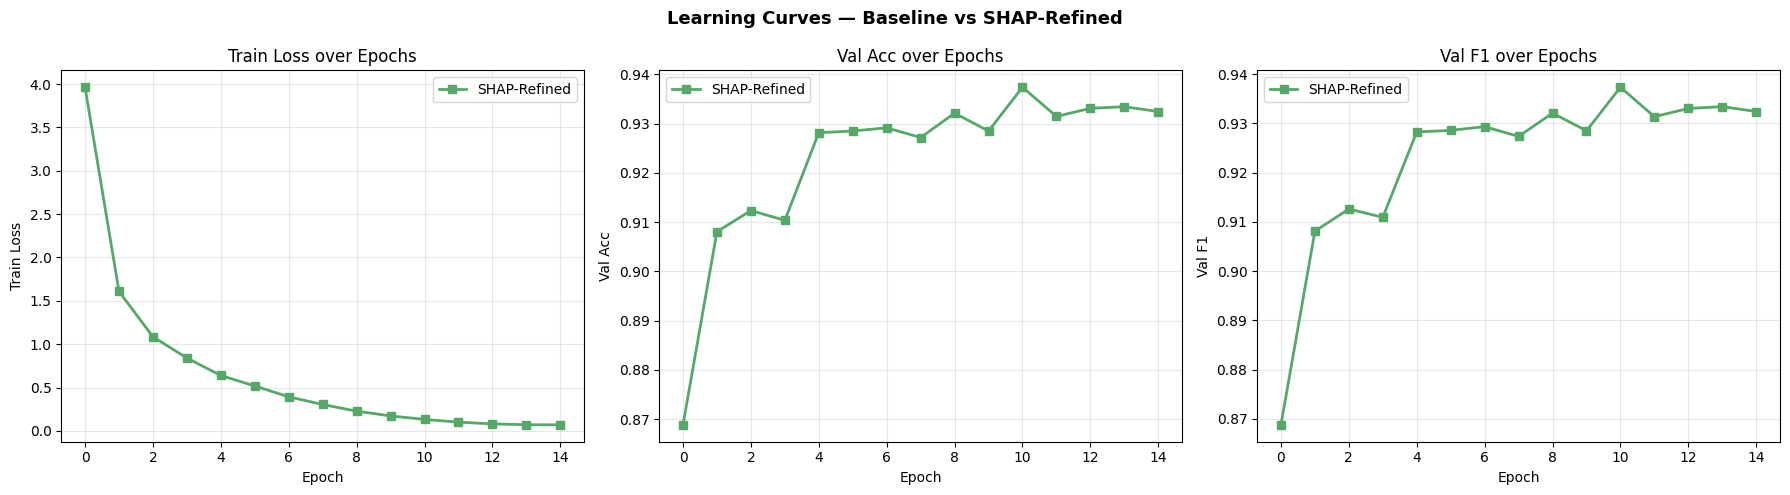

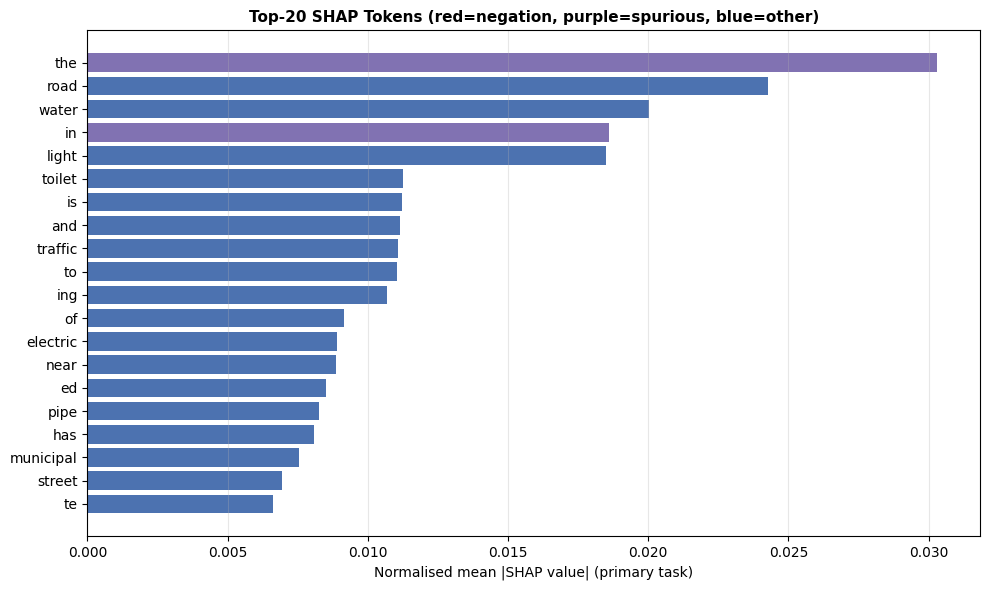

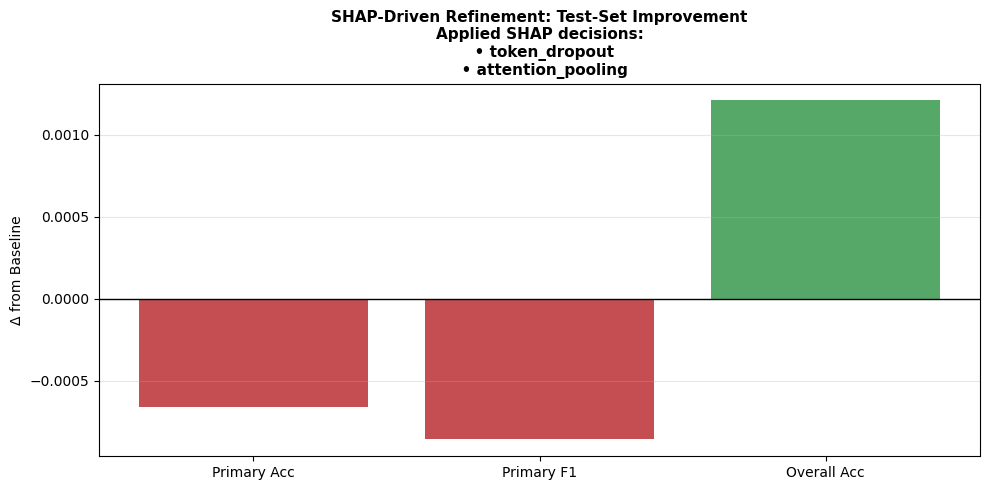


✓ All figures saved -> C:\Users\CH.SC.U4CSE23160\Final_Year_Project\hienbert_xai_refinement_results\visualizations


In [25]:
# ============================================================================
# CELL 14: PUBLICATION FIGURES
# ============================================================================
fig, ax = plt.subplots(figsize=(16, 6))
x = np.arange(len(metric_keys)); w = 0.38
b_vals = comparison_df.iloc[0][metric_keys].values.astype(float)
r_vals = comparison_df.iloc[1][metric_keys].values.astype(float)
ax.bar(x - w/2, b_vals, w, label="Baseline",     color="#4C72B0")
ax.bar(x + w/2, r_vals, w, label="SHAP-Refined", color="#55A868")
for i, (b, r) in enumerate(zip(b_vals, r_vals)):
    d = r - b
    ax.annotate(f"{d:+.3f}", (i + w/2, r + 0.005), ha="center",
                fontsize=8, color="green" if d >= 0 else "red")
ax.set_xticks(x); ax.set_xticklabels(metric_keys, rotation=45, ha="right")
ax.set_ylabel("Score"); ax.set_ylim(0, 1.05)
ax.set_title("XAI-Guided Refinement: Baseline vs SHAP-Refined",
             fontsize=13, fontweight="bold")
ax.legend(); ax.grid(True, alpha=0.3, axis="y")
plt.tight_layout()
plt.savefig(f"{Config.VISUALIZATION_DIR}/fig1_xai_refinement_metrics.png",
            dpi=300, bbox_inches="tight")
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, key, ylabel in zip(axes,
    ["train_loss", "val_acc", "val_f1"],
    ["Train Loss", "Val Acc", "Val F1"]):
    if baseline_result["history"][key]:
        ax.plot(baseline_result["history"][key], label="Baseline",
                marker="o", linewidth=2, color="#4C72B0")
    ax.plot(refined_result["history"][key], label="SHAP-Refined",
            marker="s", linewidth=2, color="#55A868")
    ax.set_title(f"{ylabel} over Epochs")
    ax.set_xlabel("Epoch"); ax.set_ylabel(ylabel)
    ax.legend(); ax.grid(alpha=0.3)
plt.suptitle("Learning Curves — Baseline vs SHAP-Refined",
             fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig(f"{Config.VISUALIZATION_DIR}/fig2_xai_learning_curves.png",
            dpi=300, bbox_inches="tight")
plt.show()

top20 = list(insights["token_importance"].items())[:20]
tokens = [t for t, _ in top20]; scores = [s for _, s in top20]
fig, ax = plt.subplots(figsize=(10, 6))
spur = [tok for d in decisions if d["type"]=="token_dropout" for tok in d.get("tokens", [])]
colors = ["#C44E52" if t in SHAPTranslator.NEGATIONS else
          ("#8172B2" if t in spur else "#4C72B0") for t in tokens]
ax.barh(range(len(tokens)), scores, color=colors)
ax.set_yticks(range(len(tokens))); ax.set_yticklabels(tokens); ax.invert_yaxis()
ax.set_xlabel("Normalised mean |SHAP value| (primary task)")
ax.set_title("Top-20 SHAP Tokens (red=negation, purple=spurious, blue=other)",
             fontsize=11, fontweight="bold")
ax.grid(True, alpha=0.3, axis="x")
plt.tight_layout()
plt.savefig(f"{Config.VISUALIZATION_DIR}/fig3_shap_tokens_refined.png",
            dpi=300, bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(10, 5))
applied = [d["type"] for d in decisions]
applied_txt = "Applied SHAP decisions:\n" + "\n".join(f"  • {a}" for a in applied)
primary_gain = float(refined_result["metrics"]["primary_acc"] - baseline_result["metrics"]["primary_acc"])
overall_gain = float(refined_result["metrics"]["overall_acc"] - baseline_result["metrics"]["overall_acc"])
f1_gain      = float(refined_result["metrics"]["primary_f1"]  - baseline_result["metrics"]["primary_f1"])
bars = ax.bar(["Primary Acc","Primary F1","Overall Acc"],
              [primary_gain, f1_gain, overall_gain],
              color=["#55A868" if v>=0 else "#C44E52"
                     for v in [primary_gain, f1_gain, overall_gain]])
for b, v in zip(bars, [primary_gain, f1_gain, overall_gain]):
    ax.annotate(f"{v:+.4f}",
                (b.get_x()+b.get_width()/2, v + (0.001 if v>=0 else -0.003)),
                ha="center", fontsize=11, fontweight="bold")
ax.axhline(0, color="black", linewidth=1)
ax.set_ylabel("Δ from Baseline")
ax.set_title("SHAP-Driven Refinement: Test-Set Improvement\n" + applied_txt,
             fontsize=11, fontweight="bold")
ax.grid(True, alpha=0.3, axis="y")
plt.tight_layout()
plt.savefig(f"{Config.VISUALIZATION_DIR}/fig4_shap_decision_impact.png",
            dpi=300, bbox_inches="tight")
plt.show()

print(f"\n✓ All figures saved -> {Config.VISUALIZATION_DIR}")

In [26]:
# ============================================================================
# CELL 15: PAPER-READY SUMMARY
# ============================================================================
print("\n" + "="*80)
print("XAI-GUIDED ITERATIVE REFINEMENT — PAPER-READY SUMMARY")
print("="*80)
print(f"\nTraining configuration (identical for both variants):")
print(f"  BATCH_SIZE={Config.BATCH_SIZE}, EPOCHS={Config.EPOCHS} (max), "
      f"LR={Config.LEARNING_RATE}, DROPOUT={Config.DROPOUT}, "
      f"WEIGHT_DECAY={Config.WEIGHT_DECAY}, WARMUP_RATIO={Config.WARMUP_RATIO}, "
      f"MAX_LENGTH={Config.MAX_LENGTH}")
print(f"  Early stopping: patience={Config.EARLY_STOPPING_PATIENCE} on val F1")

print(f"\nSHAP-driven decisions applied:")
for i, d in enumerate(decisions, 1):
    print(f"  [{i}] {d['type']}")
    print(f"       {d['rationale']}")

print(f"\nResults (test set):")
print(f"  {'Metric':<22}{'Baseline':<12}{'SHAP-Refined':<16}{'Δ':<10}")
print(f"  {'-'*60}")
for k in ["primary_acc","primary_f1","primary_bal","primary_kappa","primary_mcc",
          "subcat_acc","severity_acc","overall_acc"]:
    b = baseline_result["metrics"][k]
    r = refined_result["metrics"][k]
    print(f"  {k:<22}{b:<12.4f}{r:<16.4f}{r-b:+.4f}")

print(f"\n  Best val F1:  baseline {baseline_result['best_val_f1']:.4f} "
      f"(ep {baseline_result['best_epoch']})  →  "
      f"refined {refined_result['best_val_f1']:.4f} (ep {refined_result['best_epoch']})")

print("\n✓ Closed-loop XAI refinement complete.")
print("="*80)


XAI-GUIDED ITERATIVE REFINEMENT — PAPER-READY SUMMARY

Training configuration (identical for both variants):
  BATCH_SIZE=32, EPOCHS=15 (max), LR=2e-05, DROPOUT=0.3, WEIGHT_DECAY=0.01, WARMUP_RATIO=0.1, MAX_LENGTH=128
  Early stopping: patience=5 on val F1

SHAP-driven decisions applied:
  [1] token_dropout
       Tokens ['the', 'in'] shared across ≥4 class profiles → spurious/boilerplate; apply token dropout.
  [2] attention_pooling
       Token importance very sparse (Gini=0.72) → add attention-pooling over tokens.

Results (test set):
  Metric                Baseline    SHAP-Refined    Δ         
  ------------------------------------------------------------
  primary_acc           0.9368      0.9361          -0.0007
  primary_f1            0.9368      0.9360          -0.0009
  primary_bal           0.9396      0.9389          -0.0008
  primary_kappa         0.9270      0.9262          -0.0008
  primary_mcc           0.9271      0.9263          -0.0008
  subcat_acc            0.860